# Decision Tree on Titanic Dataset

This notebook focuses on the **Decision Tree** part of the COMM075 group coursework using the preprocessed Titanic dataset.

It will:
- inspect the cleaned Titanic data,
- train a baseline `DecisionTreeClassifier`,
- tune hyperparameters using cross-validation,
- evaluate the final model with multiple metrics,
- generate report-ready figures and tables.

Note: the shared preprocessing pipeline already scaled the features. Decision Trees do not require scaling, but the scaled values still preserve the ordering used for tree splits.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Fix seed for reproducibility across all stochastic steps
RANDOM_STATE = 42

In [2]:
def find_project_root(start: Path) -> Path:
    """Walk up from *start* until we find the datasets/cleaned directory."""
    for candidate in [start, *start.parents]:
        if all((candidate / "datasets" / "cleaned" / f).exists()
               for f in ["titanic_X_train.csv", "titanic_X_val.csv",
                          "titanic_y_train.csv", "titanic_y_val.csv"]):
            return candidate
    raise FileNotFoundError("Could not locate project root.")

PROJECT_ROOT = find_project_root(Path.cwd())
CLEANED_DIR  = PROJECT_ROOT / "datasets" / "cleaned"
OUTPUT_DIR   = PROJECT_ROOT / "Decision_Tree" / "outputs_titanic"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Cleaned dir :", CLEANED_DIR)
print("Output dir  :", OUTPUT_DIR)

Project root: /user/HS401/sn01556/Desktop/MLDS/mlds-group5-project
Cleaned dir : /user/HS401/sn01556/Desktop/MLDS/mlds-group5-project/datasets/cleaned
Output dir  : /user/HS401/sn01556/Desktop/MLDS/mlds-group5-project/Decision_Tree/outputs_titanic


In [3]:
X_train = pd.read_csv(CLEANED_DIR / "titanic_X_train.csv")
X_val = pd.read_csv(CLEANED_DIR / "titanic_X_val.csv")
y_train = pd.read_csv(CLEANED_DIR / "titanic_y_train.csv")["Survived"]
y_val = pd.read_csv(CLEANED_DIR / "titanic_y_val.csv")["Survived"]

print("X_train shape:", X_train.shape)
print("X_val shape:  ", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:  ", y_val.shape)

X_train shape: (712, 13)
X_val shape:   (179, 13)
y_train shape: (712,)
y_val shape:   (179,)


In [4]:
inspection_summary = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "train_missing": X_train.isna().sum(),
    "val_missing": X_val.isna().sum(),
    "unique_values": X_train.nunique(),
})

inspection_summary

,dtype,train_missing,val_missing,unique_values
Pclass,float64,0,0,3
Sex,float64,0,0,2
Age,float64,0,0,87
SibSp,float64,0,0,7
Parch,float64,0,0,7
Fare,float64,0,0,226
Embarked,float64,0,0,3
Title,float64,0,0,5
FamilySize,float64,0,0,9
IsAlone,float64,0,0,2


In [5]:
print("Training target distribution")
display(y_train.value_counts().rename("count").to_frame())
display((y_train.value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())

print("Validation target distribution")
display(y_val.value_counts().rename("count").to_frame())
display((y_val.value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())

Training target distribution


,count
Survived,
0,439
1,273


,percent
Survived,
0,61.66
1,38.34


Validation target distribution


,count
Survived,
0,110
1,69


,percent
Survived,
0,61.45
1,38.55


In [6]:
train_with_target = X_train.copy()
train_with_target["Survived"] = y_train

feature_corr = (
    train_with_target.corr(numeric_only=True)["Survived"]
    .drop("Survived")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

feature_corr.to_frame("correlation_with_survived")

,correlation_with_survived
Sex,0.549171
Fare,0.355094
CabinKnown,0.350535
Pclass,-0.348007
FareBand,0.325867
IsAlone,-0.215570
Embarked,0.142687
AgeBand,-0.103520
Parch,0.084178
Age,-0.065353


## Baseline Model

We start with a baseline Decision Tree before tuning. This gives us a reference point for later comparisons.

In [7]:
def evaluate_model(model, X_train, y_train, X_val, y_val, model_name="Model"):
    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)
    y_train_proba = model.predict_proba(X_train)[:, 1]
    y_val_proba = model.predict_proba(X_val)[:, 1]

    metrics = pd.DataFrame(
        {
            "Accuracy": [accuracy_score(y_train, y_train_pred), accuracy_score(y_val, y_val_pred)],
            "F1": [f1_score(y_train, y_train_pred), f1_score(y_val, y_val_pred)],
            "ROC_AUC": [roc_auc_score(y_train, y_train_proba), roc_auc_score(y_val, y_val_proba)],
        },
        index=["Train", "Validation"],
    ).round(4)

    print(model_name)
    display(metrics)
    print("Validation classification report")
    print(classification_report(y_val, y_val_pred, digits=4))

    return {
        "metrics": metrics,
        "y_val_pred": y_val_pred,
        "y_val_proba": y_val_proba,
        "y_train_pred": y_train_pred,
        "y_train_proba": y_train_proba,
    }

In [8]:
baseline_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline_tree.fit(X_train, y_train)

baseline_results = evaluate_model(
    baseline_tree,
    X_train,
    y_train,
    X_val,
    y_val,
    model_name="Baseline Decision Tree",
)


Baseline Decision Tree


,Accuracy,F1,ROC_AUC
Train,0.9874,0.9833,0.9996
Validation,0.7654,0.7000,0.7434


Validation classification report
              precision    recall  f1-score   support

           0     0.8148    0.8000    0.8073       110
           1     0.6901    0.7101    0.7000        69

    accuracy                         0.7654       179
   macro avg     0.7525    0.7551    0.7537       179
weighted avg     0.7668    0.7654    0.7660       179



In [9]:
# StratifiedKFold preserves the ~62/38 class ratio in every fold,
# which matters here since the dataset is moderately imbalanced.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

baseline_cv = cross_validate(
    baseline_tree,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
)

baseline_cv_summary = pd.DataFrame({
    metric: [baseline_cv[f"test_{metric}"].mean(), baseline_cv[f"test_{metric}"].std()]
    for metric in scoring
}, index=["mean", "std"]).round(4)

baseline_cv_summary

,accuracy,f1,roc_auc
mean,0.8006,0.7427,0.7917
std,0.0174,0.0230,0.0235


## Hyperparameter Tuning

A default Decision Tree can overfit badly. We therefore search for a more generalisable tree using cross-validation.

In [10]:
# Search over splitting criterion, depth, sample constraints, and class weighting.
# class_weight="balanced" upweights the minority class (survivors) — important for F1.
# max_depth controls tree complexity and is the primary lever against overfitting.
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "class_weight": [None, "balanced"],
}

# Optimise for F1 because accuracy is misleading on an imbalanced target.
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,  # refit the best model on the full training set automatically
    verbose=1,
)

grid_search.fit(X_train, y_train)

print("Best cross-validation F1:", round(grid_search.best_score_, 4))
print("Best parameters:")
grid_search.best_params_

Fitting 5 folds for each of 448 candidates, totalling 2240 fits
Best cross-validation F1: 0.7647
Best parameters:


{'class_weight': 'balanced',
 'criterion': 'gini',
 'max_depth': 4,
 'min_samples_leaf': 1,
 'min_samples_split': 20}

In [11]:
cv_results = pd.DataFrame(grid_search.cv_results_)
top_models = cv_results.sort_values("rank_test_score").loc[:, [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "param_criterion",
    "param_max_depth",
    "param_min_samples_split",
    "param_min_samples_leaf",
    "param_class_weight",
]].head(10)

top_models

,rank_test_score,mean_test_score,std_test_score,param_criterion,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_class_weight
243,1,0.764744,0.031318,gini,4,20,1,balanced
247,2,0.763401,0.032247,gini,4,20,2,balanced
359,3,0.763161,0.032892,entropy,4,20,2,balanced
355,3,0.763161,0.032892,entropy,4,20,1,balanced
240,5,0.762671,0.036686,gini,4,2,1,balanced
242,6,0.761312,0.027795,gini,4,10,1,balanced
352,7,0.761216,0.037293,entropy,4,2,1,balanced
251,8,0.761114,0.028500,gini,4,20,4,balanced
363,9,0.760787,0.029392,entropy,4,20,4,balanced
246,10,0.759969,0.028677,gini,4,10,2,balanced


In [12]:
# best_estimator_ is already refit on the full X_train by GridSearchCV (refit=True).
best_tree = grid_search.best_estimator_

best_results = evaluate_model(
    best_tree,
    X_train,
    y_train,
    X_val,
    y_val,
    model_name="Tuned Decision Tree",
)

Tuned Decision Tree


,Accuracy,F1,ROC_AUC
Train,0.8230,0.7857,0.8882
Validation,0.7374,0.6928,0.8090


Validation classification report
              precision    recall  f1-score   support

           0     0.8316    0.7182    0.7707       110
           1     0.6310    0.7681    0.6928        69

    accuracy                         0.7374       179
   macro avg     0.7313    0.7431    0.7318       179
weighted avg     0.7542    0.7374    0.7407       179



In [13]:
comparison_table = pd.concat(
    {
        "Baseline": baseline_results["metrics"],
        "Tuned": best_results["metrics"],
    },
    axis=0,
).reset_index().rename(columns={"level_0": "Model", "level_1": "Split"})

comparison_table

,Model,Split,Accuracy,F1,ROC_AUC
0,Baseline,Train,0.9874,0.9833,0.9996
1,Baseline,Validation,0.7654,0.7000,0.7434
2,Tuned,Train,0.8230,0.7857,0.8882
3,Tuned,Validation,0.7374,0.6928,0.8090


## Tuned Model Cross-Validation Summary

In [14]:
# Re-run cross-validation on the tuned model so results are formatted
# identically to baseline_cv_summary — making the comparison table directly usable in the report.
tuned_cv = cross_validate(
    best_tree,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
)

tuned_cv_summary = pd.DataFrame({
    metric: [tuned_cv[f"test_{metric}"].mean(), tuned_cv[f"test_{metric}"].std()]
    for metric in scoring
}, index=["mean", "std"]).round(4)

cv_comparison = pd.concat(
    {"Baseline": baseline_cv_summary, "Tuned": tuned_cv_summary},
    axis=0,
).reset_index().rename(columns={"level_0": "Model", "level_1": "Stat"})

print("Cross-Validation comparison (5-fold, on training set)")
display(cv_comparison)


Cross-Validation comparison (5-fold, on training set)


,Model,Stat,accuracy,f1,roc_auc
0,Baseline,mean,0.8006,0.7427,0.7917
1,Baseline,std,0.0174,0.0230,0.0235
2,Tuned,mean,0.8161,0.7647,0.8552
3,Tuned,std,0.0253,0.0313,0.0272


## Validation Confusion Matrix

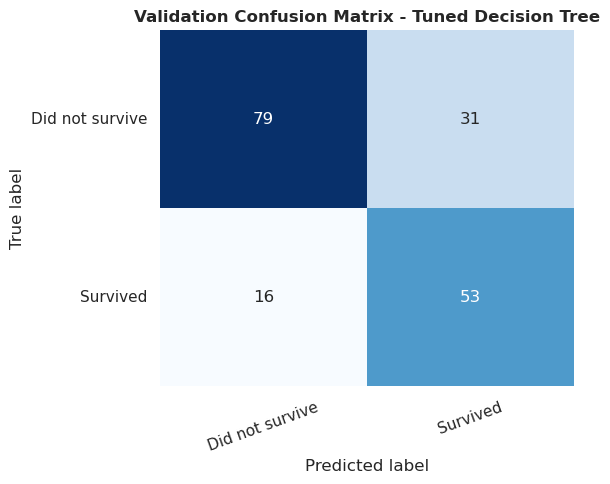

In [15]:
cm = confusion_matrix(y_val, best_results["y_val_pred"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Validation Confusion Matrix - Tuned Decision Tree", fontweight="bold")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticklabels(["Did not survive", "Survived"], rotation=20)
ax.set_yticklabels(["Did not survive", "Survived"], rotation=0)
plt.tight_layout()
# dpi=200 keeps file size reasonable while staying sharp in the report
plt.savefig(OUTPUT_DIR / "confusion_matrix_validation.png", dpi=200, bbox_inches="tight")
plt.show()

## ROC Curve

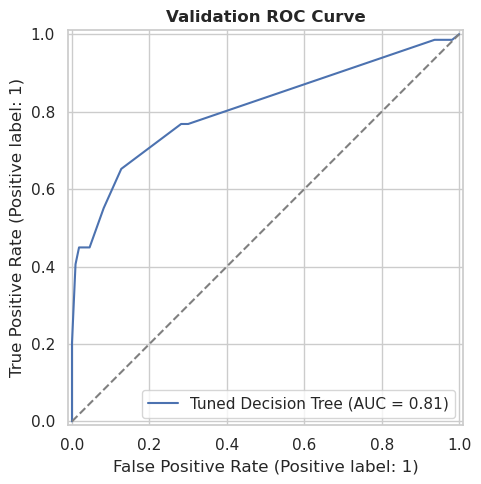

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_val,
    best_results["y_val_proba"],
    ax=ax,
    name="Tuned Decision Tree",
)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_title("Validation ROC Curve", fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve_validation.png", dpi=200, bbox_inches="tight")
plt.show()

## ROC Curve Comparison: Baseline vs Tuned

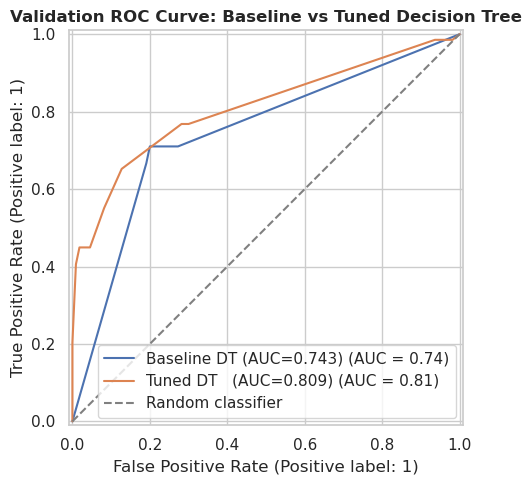

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    y_val,
    baseline_results["y_val_proba"],
    ax=ax,
    name=f"Baseline DT (AUC={baseline_results['metrics'].loc['Validation', 'ROC_AUC']:.3f})",
)
RocCurveDisplay.from_predictions(
    y_val,
    best_results["y_val_proba"],
    ax=ax,
    name=f"Tuned DT   (AUC={best_results['metrics'].loc['Validation', 'ROC_AUC']:.3f})",
)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_title("Validation ROC Curve: Baseline vs Tuned Decision Tree", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


## Feature Importance

In [18]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": best_tree.feature_importances_,
}).sort_values("importance", ascending=False)

feature_importance

,feature,importance
1,Sex,0.592358
10,CabinKnown,0.105919
2,Age,0.101182
0,Pclass,0.098543
8,FamilySize,0.044163
5,Fare,0.042304
6,Embarked,0.015530
3,SibSp,0.000000
4,Parch,0.000000
7,Title,0.000000


## Zero-Importance Features

In [19]:
# Features with zero importance were never chosen as a split criterion by the tuned tree.
# This is useful for the report: it indicates these features add no discriminative power
# at depth<=4, and could be dropped from future experiments to simplify the model.
zero_importance = feature_importance[feature_importance["importance"] == 0]
nonzero_importance = feature_importance[feature_importance["importance"] > 0]

print(f"Features used by the tree ({len(nonzero_importance)}):")
display(nonzero_importance.reset_index(drop=True))

print(f"\nFeatures with zero importance — never selected as a split ({len(zero_importance)}):")
display(zero_importance.reset_index(drop=True))


Features used by the tree (7):


,feature,importance
0,Sex,0.592358
1,CabinKnown,0.105919
2,Age,0.101182
3,Pclass,0.098543
4,FamilySize,0.044163
5,Fare,0.042304
6,Embarked,0.015530



Features with zero importance — never selected as a split (6):


,feature,importance
0,SibSp,0.0
1,Parch,0.0
2,Title,0.0
3,IsAlone,0.0
4,FareBand,0.0
5,AgeBand,0.0


/tmp/ipykernel_141027/2065401793.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance, x="importance", y="feature", palette="viridis", ax=ax)


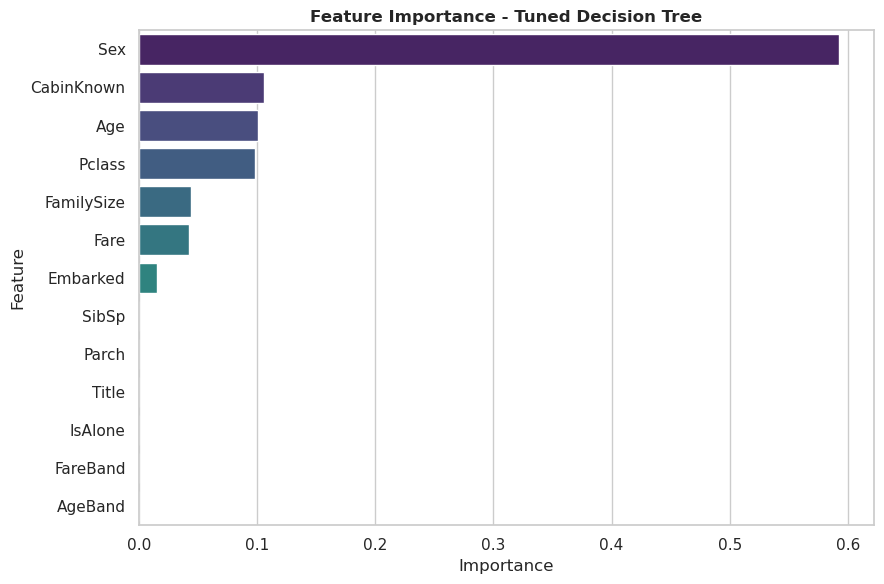

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=feature_importance, x="importance", y="feature", palette="viridis", ax=ax)
ax.set_title("Feature Importance - Tuned Decision Tree", fontweight="bold")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()
# Sex dominates — consistent with historical Titanic survival data (women/children first policy).

## Tree Visualisation

For readability, the plot below is limited to the upper part of the tree. This is usually more useful in the report than plotting every node.

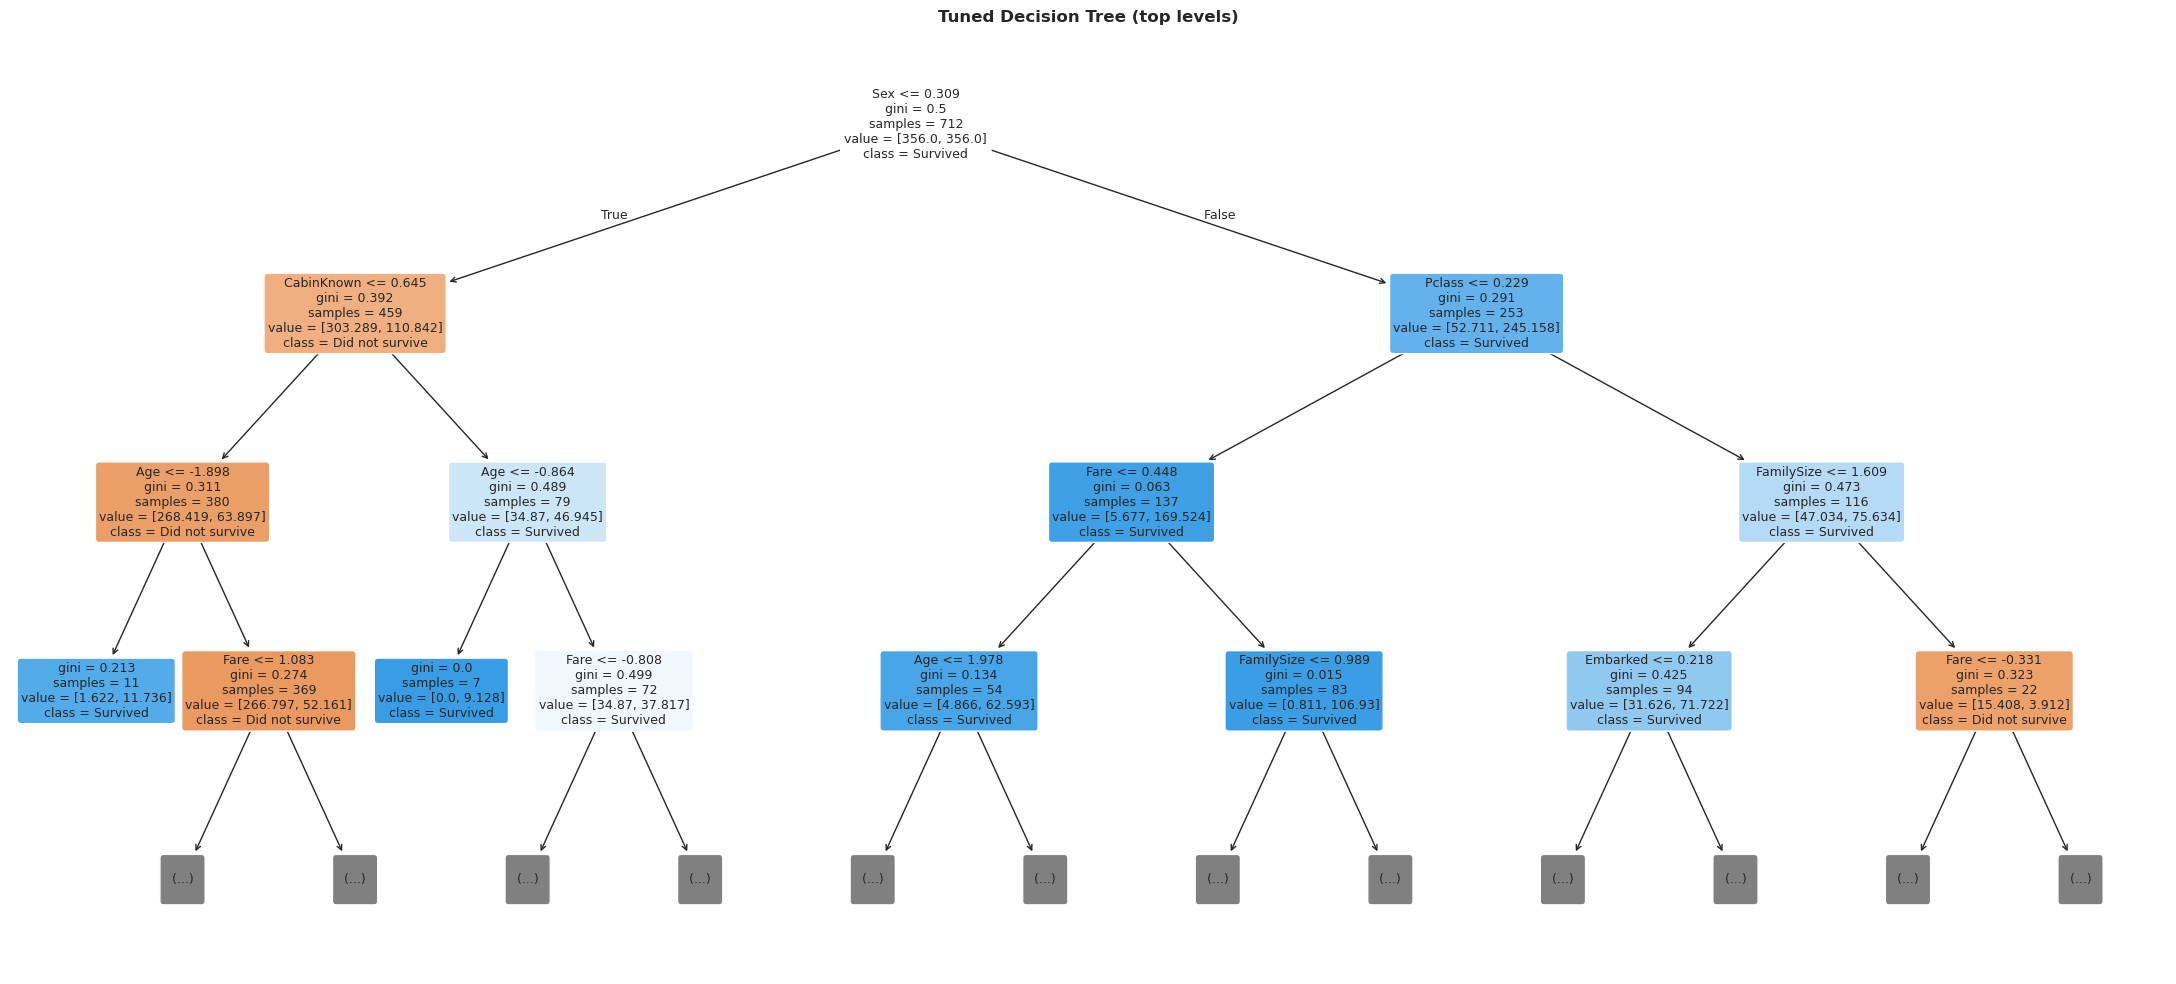

In [21]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    best_tree,
    feature_names=X_train.columns,
    class_names=["Did not survive", "Survived"],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3,
    ax=ax,
)
ax.set_title("Tuned Decision Tree (top levels)", fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "decision_tree_top_levels.png", dpi=200, bbox_inches="tight")
plt.show()

## Report Notes

Use this section to turn the outputs into report-ready observations.

In [22]:
top_features = feature_importance.head(5)["feature"].tolist()

report_notes = [
    "The Decision Tree was evaluated on the preprocessed Titanic dataset using a stratified training/validation split.",
    "Model selection was performed with 5-fold stratified cross-validation and hyperparameter tuning via GridSearchCV.",
    f"The best model parameters were: {grid_search.best_params_}.",
    f"The five most influential features were: {', '.join(top_features)}.",
    "The final evaluation should discuss both predictive performance and interpretability, since a Decision Tree is valuable for explaining which passenger characteristics most affect survival predictions.",
]

for i, note in enumerate(report_notes, start=1):
    print(f"{i}. {note}")

1. The Decision Tree was evaluated on the preprocessed Titanic dataset using a stratified training/validation split.
2. Model selection was performed with 5-fold stratified cross-validation and hyperparameter tuning via GridSearchCV.
3. The best model parameters were: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 20}.
4. The five most influential features were: Sex, CabinKnown, Age, Pclass, FamilySize.
5. The final evaluation should discuss both predictive performance and interpretability, since a Decision Tree is valuable for explaining which passenger characteristics most affect survival predictions.


In [23]:
comparison_table.to_csv(OUTPUT_DIR / "decision_tree_metrics_comparison.csv", index=False)
feature_importance.to_csv(OUTPUT_DIR / "decision_tree_feature_importance.csv", index=False)
top_models.to_csv(OUTPUT_DIR / "decision_tree_top_gridsearch_results.csv", index=False)

print("Saved outputs:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

Saved outputs:
- confusion_matrix_validation.png
- decision_tree_feature_importance.csv
- decision_tree_metrics_comparison.csv
- decision_tree_top_gridsearch_results.csv
- decision_tree_top_levels.png
- feature_importance.png
- roc_curve_comparison.png
- roc_curve_validation.png
